In [ ]:
!pip install -q pandas matplotlib openpyxl numpy

cell 2


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ---- matplotlib publication styling ----------------------------------------
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

# ---- energy window for comparison -------------------------------------------
E_MIN, E_MAX = 1.0, 20.0          # MeV  — range where ALL five sources are present
                                  #   (JEFF & TALYS start at 1 MeV; ENDF/JENDL ends at 20 MeV)

# ---- expected file names (rename your uploads to match, or edit here) -------
#  NOTE: the upload names from this project map to the canonical names below.
FILES = {
    "EXFOR":   "Fe-54_n_p_Mn-54_exfor.csv",                              # experimental
    "TENDL":   "Fe54__tendl.csv",                                        # TENDL-2023
    "ENDF_B":  "FE-54(N,P)MN-54, cross section data B-VIII.1.txt",       # evaluated (eV/barn)
    "JENDL_5": "Fe 54 (n,p) cross section data jendl 200 MeV endf",      # JENDL-5 (eV/barn)
    "JEFF":    "JEFF_Fe54_np_CrossSection_1MeV_to_40MeV.csv",            # JEFF
    "TALYS":   "TALYS_DATA_for_Fe_54__csv.xlsx",                         # TALYS predictions
}

# Fallback aliases so the generic names in the task brief also work.
ALIASES = {
    "EXFOR":   ["EXFOR_Fe54_np.txt", "EXFOR_Fe54_np.csv"],
    "TENDL":   ["TENDL_Fe54_np.csv"],
    "ENDF_B":  ["ENDF_Fe54_np.txt", "FE-54(N,P)MN-54, cross section data B-VIII.1.txt"],
    "JENDL_5": ["Fe 54 (n,p) cross section data jendl 200 MeV endf"],
    "JEFF":    ["JEFF_Fe54_np.csv"],
    "TALYS":   ["TALYS_Fe54_np.xlsx"],
}

def _norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")

def resolve(key):
    # Map internal keys to normalized string parts expected in filenames
    key_to_filename_part = {
        "EXFOR": "exfor",
        "TENDL": "tendl",
        "ENDF_B":  "b-viii.1", # Specific to the B-VIII.1 file
        "JEFF":  "jeff",
        "TALYS": "talys",
        "JENDL_5": "jendl", # Specific to the JENDL file
    }
    want_part = key_to_filename_part.get(key)
    if not want_part:
        return None # Should not happen if `key` is always from `FILES`

    # List of possible filenames for the given key (exact matches first)
    possible_filenames = [FILES[key]] if key in FILES else []
    possible_filenames.extend(ALIASES.get(key, []))

    for fn in os.listdir("."):
        # Check for exact matches first
        if fn in possible_filenames:
            return fn
        # Then check for substring match in normalized filename
        n = _norm(fn)
        if want_part in n:
            return fn
    return None

B_TO_MB = 1000.0   # barns -> millibarns
EV_TO_MEV = 1e-6   # eV    -> MeV



cell 3


In [ ]:
def parse_exfor(path):
    """EXFOR experimental CSV: energy_MeV, cross_section_b, uncertainties,
    author, year. Returns a tidy DataFrame in MeV / mb."""
    df = pd.read_csv(path)
    out = pd.DataFrame({
        "energy_MeV":  pd.to_numeric(df["energy_MeV"], errors="coerce"),
        "xs_mb":       pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB,
        "dE_MeV":      pd.to_numeric(df.get("d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":      pd.to_numeric(df.get("d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":      df.get("author", "Unknown").astype(str).str.strip(),
        "year":        pd.to_numeric(df.get("year", 0), errors="coerce").fillna(0).astype(int),
    })
    out = out.dropna(subset=["energy_MeV", "xs_mb"])
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0]
    # human-readable "Author (Year)" label used for color-coding
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out.reset_index(drop=True)


def parse_tendl(path):
    """TENDL CSV (TALYS YANDF export). Data already in MeV / mb;
    a long '#'-comment header precedes 'E,xs'."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(',').strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if s.lower().startswith("e,") or s.lower() == "e,xs":
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                e  = float(parts[0])
                xs = float(parts[1])
            except ValueError:
                continue
            rows.append((e, xs))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])  # already MeV, mb
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_endf(path):
    """ENDF / JENDL point file: 'E[eV]  Sig[b]  Interpolation'.
    Lines beginning with '#' are header. Convert eV->MeV, b->mb."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()
            if len(parts) < 2:
                continue
            try:
                e_ev  = float(parts[0])
                sig_b = float(parts[1])
            except ValueError:
                continue
            rows.append((e_ev * EV_TO_MEV, sig_b * B_TO_MB))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_b_viii_1(path):
    """Parser for FE-54(N,P)MN-54, cross section data B-VIII.1.txt.
    Assumes similar format to ENDF / JENDL point files (E[eV] Sig[b])."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()
            if len(parts) < 2:
                continue
            try:
                e_ev  = float(parts[0])
                sig_b = float(parts[1])
            except ValueError:
                continue
            rows.append((e_ev * EV_TO_MEV, sig_b * B_TO_MB))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_jeff(path):
    """JEFF CSV with columns Energy_eV, CrossSection_barns, Energy_MeV."""
    df = pd.read_csv(path)
    if "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    out = pd.DataFrame({"energy_MeV": e, "xs_mb": xs}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)


def parse_talys(path):
    """TALYS xlsx: 4 side-by-side (Energy[MeV], sigma[mb]) blocks, one per
    level-density model. Returns a dict {model_name: DataFrame}."""
    raw = pd.read_excel(path, header=None)
    titles = raw.iloc[0].tolist()

    # Short display names for the 4 TALYS level-density models
    MODEL_NAMES = {
        "constanttemperature": "CTM",
        "generalizedsuperfluid": "GSM",
        "backshiftedfermigas": "BSFM",
        "microscopic": "Microscopic (Skyrme)",
    }

    def key_for(title):
        t = str(title).lower().replace(" ", "").replace("", "")
        if "constanttemperature" in t or "ctm" in t:
            return "constanttemperature"
        if "generalizedsuperfluid" in t or "gsm" in t:
            return "generalizedsuperfluid"
        if "backshifted" in t or "bsfm" in t or "bfm" in t:
            return "backshiftedfermigas"
        if "microscopic" in t or "skyrme" in t:
            return "microscopic"
        return None

    models = {}
    for i, t in enumerate(titles):
        if not isinstance(t, str):
            continue
        k = key_for(t)
        if k is None:
            continue
        e  = pd.to_numeric(raw.iloc[2:, i],     errors="coerce")
        xs = pd.to_numeric(raw.iloc[2:, i + 1], errors="coerce")
        df = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
        df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
        df = df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)
        models[MODEL_NAMES[k]] = df

    return models

# ---- load everything, handling missing files gracefully --------------------
PARSERS = {
    "EXFOR":   parse_exfor,
    "TENDL":   parse_tendl,
    "ENDF_B":  parse_b_viii_1, # Uses the B-VIII.1 parser
    "JENDL_5": parse_endf,     # Uses the generic ENDF parser for JENDL data
    "JEFF":    parse_jeff,
    "TALYS":   parse_talys,
}

data = {}
for key, parser in PARSERS.items():
    path = resolve(key)
    if path is None:
        print(f"[WARNING] {key}: file not found "
              f"(looked for '{FILES.get(key, 'N/A')}' and aliases) — skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        print(f"[OK] {key:5s}: {len(data[key]):4d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None

[OK] EXFOR:  453 points  from 'Fe-54_n_p_Mn-54 exfor.csv'
[OK] TENDL:   55 points  from 'Fe54  tendl.csv'
[OK] ENDF_B:  729 points  from 'FE-54(N,P)MN-54, cross section data B-VIII.1.txt'
[OK] JENDL_5:  690 points  from 'Fe 54 ( n,p ) cross section data jendl 200 MeV endf.txt'
[OK] JEFF :   89 points  from 'JEFF_Fe54_np_CrossSection_1MeV_to_40MeV.csv'
[OK] TALYS:    4 points  from 'TALYS DATA for Fe 54 .csv.xlsx'


cell 4


Fe54_np_combined_comparison_plot_b_viii_1.png: 1554.3 KB
fe54_np_comparison.pdf: 62.4 KB
fe54_np_comparison.eps: 172.7 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

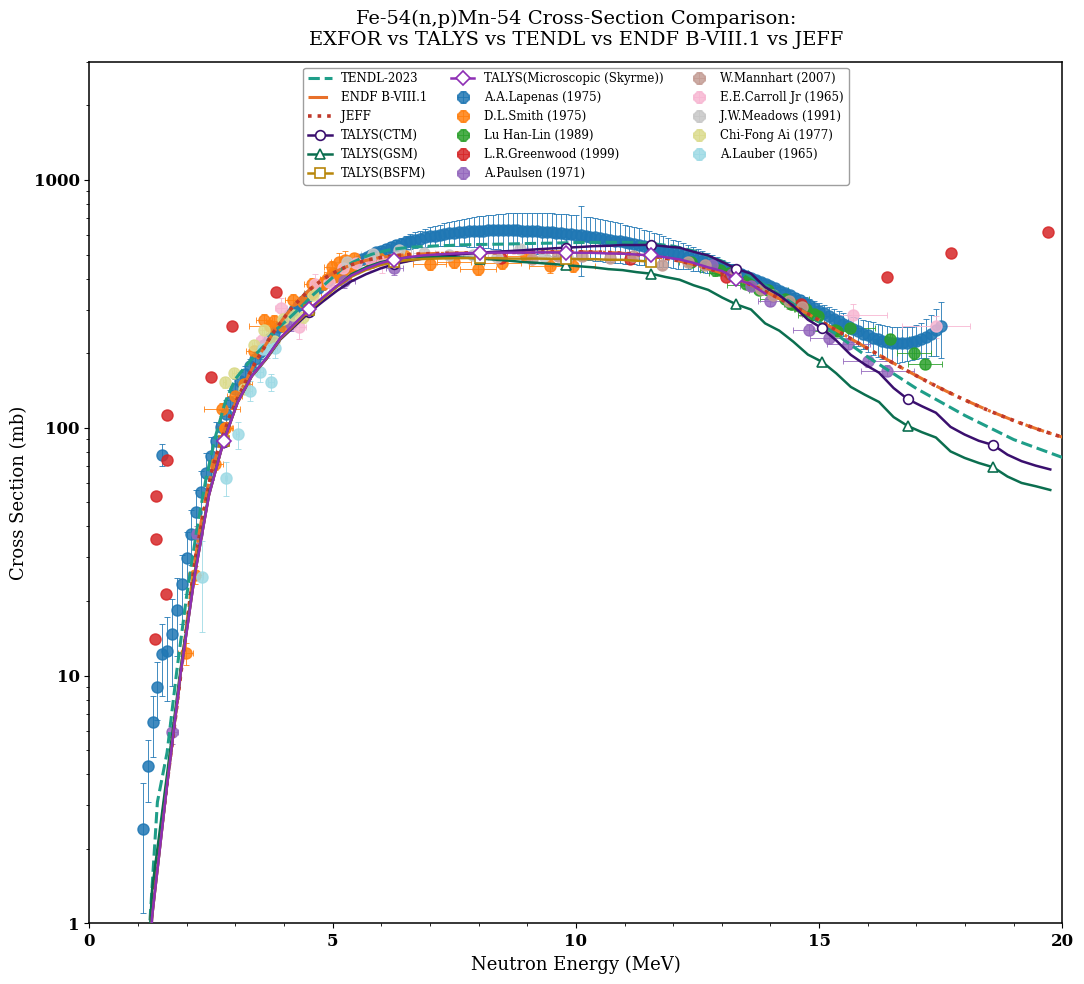

In [ ]:
import matplotlib.pyplot as plt
import shutil
from google.colab import files
from matplotlib.ticker import LogLocator, MultipleLocator, NullFormatter
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(11, 10))

# ---- theoretical / evaluated curves -----------------------------------------
CURVE_STYLE = {
    "TENDL":   dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF_B":  dict(color="#e8702a", ls="-.", lw=2.2, label="ENDF B-VIII.1"),
    "JEFF":    dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TENDL", "ENDF_B", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

# ---- TALYS: 4 level-density models, distinct colors + markers --------------
TALYS_STYLE = {
    "CTM":                  dict(color="#3a0f6e", marker="o", markevery=6, ls="-",  lw=1.8),
    "GSM":                  dict(color="#0b6e4f", marker="^", markevery=6, ls="-",  lw=1.8),
    "BSFM":                 dict(color="#b8860b", marker="s", markevery=6, ls="-",  lw=1.8),
    "Microscopic (Skyrme)": dict(color="#8e2fb5", marker="D", markevery=6, ls="-",  lw=1.8),
}
talys_models = data.get("TALYS")
if talys_models:
    for name, df in talys_models.items():
        if df is not None and len(df):
            style = TALYS_STYLE.get(name, dict(color="gray", marker="x", ls="-", lw=1.5))
            ax.plot(df["energy_MeV"], df["xs_mb"],
                     markersize=7, markerfacecolor="white", markeredgewidth=1.2,
                     label=f"TALYS({name})", zorder=3, **style)

# ---- EXFOR experimental points, color-coded by author/year ------------------
exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    TOP_N = 10
    counts = exfor["label"].value_counts()
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor.copy()
    # exfor["plot_label"] = np.where(exfor["label"].isin(top_labels),
    #                                exfor["label"], "Other measurements")

    # plot_labels = top_labels + (["Other measurements"]
    #                             if (exfor["plot_label"] == "Other measurements").any()
    #                             else [])

    # keep ONLY the top-N authors; drop everything else (no "Other measurements")
    exfor = exfor[exfor["label"].isin(top_labels)].copy()
    exfor["plot_label"] = exfor["label"]

    plot_labels = top_labels


    cmap = plt.cm.tab20(np.linspace(0, 1, max(len(plot_labels), 1)))
    # Changed to use a single marker and adjusted error bar appearance
    # markers = ["o", "s", "^", "v", "D", "<", ">", "p", "*", "h", "X", "P"]

    for i, lab in enumerate(plot_labels):
        sub = exfor[exfor["plot_label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt='o', # Use a consistent circle marker
            color=cmap[i], ecolor=cmap[i],
            markersize=8, capsize=2, elinewidth=0.7, capthick=0.7, # Adjusted size and width
            linestyle="none", alpha=0.85, label=lab, zorder=2,
        )

# ---- axes scales and range --------------------------------------------------
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0, 20)
ax.set_ylim(1, 3000)

# Set x-axis ticks
ax.set_xticks([0, 5, 10, 15, 20])
# Set y-axis ticks
ax.set_yticks([1, 10, 100, 1000])
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())             # headroom above ~550 mb peak for the legend

ax.set_xlabel("Neutron Energy (MeV)", fontsize=13)
ax.set_ylabel("Cross Section (mb)", fontsize=13)
ax.set_title(
    "Fe-54(n,p)Mn-54 Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs ENDF B-VIII.1 vs JEFF", # UPDATED title
    fontsize=14, pad=12,
)

# ---- X AXIS (linear): major ticks at 5, 10, 15, 20; minor every 1 -----------
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))

# ---- Y AXIS (log): major ticks at decades 10, 100, 1000; minor sub-decade ---
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())

# Remove grid lines
# ax.grid(which="major", ls="-",  lw=0.6, alpha=0.5)
# ax.grid(which="minor", ls=":",  lw=0.4, alpha=0.3)

# Make x and y axis tick labels bold
for tick_label in ax.get_xticklabels():
    tick_label.set_fontsize(12)
    tick_label.set_fontweight('bold')
for tick_label in ax.get_yticklabels():
    tick_label.set_fontsize(12)
    tick_label.set_fontweight('bold')

ax.legend(loc="upper center", ncol=3, fontsize=8.5,
          framealpha=0.95, edgecolor="0.6")

fig.tight_layout()

OUT_PNG = "Fe54_np_combined_comparison_plot_b_viii_1.png"
OUT_PDF = "fe54_np_comparison.pdf"
OUT_EPS = "fe54_np_comparison.eps"

# Save all three (make sure this runs in the same cell as your plotting code, right after fig.tight_layout())
plt.savefig(OUT_PNG, dpi=600, bbox_inches='tight')
plt.savefig(OUT_PDF, bbox_inches='tight')
plt.savefig(OUT_EPS, bbox_inches='tight')

# Verify PNG actually exists and check its size before zipping
import os
for f in [OUT_PNG, OUT_PDF, OUT_EPS]:
    if os.path.exists(f):
        print(f"{f}: {os.path.getsize(f)/1024:.1f} KB")
    else:
        print(f"MISSING: {f}")

# Zip everything into one file and download once
shutil.make_archive("fe54_np_figures", 'zip', '.', base_dir=None) if False else None
import zipfile
with zipfile.ZipFile("fe54_np_figures.zip", "w") as zf:
    for f in [OUT_PNG, OUT_PDF, OUT_EPS]:
        if os.path.exists(f):
            zf.write(f)

files.download("fe54_np_figures.zip")

cell 5


In [ ]:
# ---- flatten TALYS dict {model_name: df} into separate sources -------------
flat_data = {}
for key, val in data.items():
    if key == "TALYS" and isinstance(val, dict):
        for model_name, df in val.items():
            flat_data[f"TALYS_{model_name}"] = df
    else:
        flat_data[key] = val

frames = []
for key, df in flat_data.items():
    if df is None or not len(df):
        continue
    tmp = df.copy()
    tmp["source"] = key
    if key == "EXFOR":
        tmp = tmp[["source", "energy_MeV", "xs_mb", "dE_MeV", "dxs_mb",
                   "author", "year"]]
    else:
        tmp = tmp[["source", "energy_MeV", "xs_mb"]]
        tmp["dE_MeV"] = np.nan
        tmp["dxs_mb"] = np.nan
        tmp["author"] = np.nan
        tmp["year"]   = np.nan
    frames.append(tmp)

combined = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
combined = combined.sort_values(["source", "energy_MeV"]).reset_index(drop=True)

OUT_CSV = "Fe54_np_parsed_data.csv"
combined.to_csv(OUT_CSV, index=False)
print(f"Saved data -> {OUT_CSV}  ({len(combined)} rows)")

# ---- summary statistics file ------------------------------------------------
OUT_TXT = "Fe54_np_summary_statistics.txt"
with open(OUT_TXT, "w") as f:
    f.write("Fe-54(n,p)Mn-54 Cross-Section Data — Summary Statistics\n")
    f.write("=" * 60 + "\n")
    f.write(f"Comparison energy window: {E_MIN}-{E_MAX} MeV\n\n")
    for key, df in flat_data.items():
        f.write(f"[{key}]\n")
        if df is None or not len(df):
            f.write("  (no data / file missing)\n\n")
            continue
        f.write(f"  points        : {len(df)}\n")
        f.write(f"  energy range  : {df['energy_MeV'].min():.4g} - "
                f"{df['energy_MeV'].max():.4g} MeV\n")
        f.write(f"  xs min        : {df['xs_mb'].min():.4g} mb\n")
        f.write(f"  xs max        : {df['xs_mb'].max():.4g} mb\n")
        if key == "EXFOR":
            f.write(f"  unique authors: {df['author'].nunique()}\n")
            f.write(f"  year range    : {int(df['year'].min())}-"
                    f"{int(df['year'].max())}\n")
        f.write("\n")
print(f"Saved stats -> {OUT_TXT}")
print("\n".join(open(OUT_TXT).read().splitlines()))

Saved data -> Fe54_np_parsed_data.csv  (2228 rows)
Saved stats -> Fe54_np_summary_statistics.txt
Fe-54(n,p)Mn-54 Cross-Section Data — Summary Statistics
Comparison energy window: 1.0-20.0 MeV

[EXFOR]
  points        : 453
  energy range  : 1 - 19.7 MeV
  xs min        : 0.01373 mb
  xs max        : 627 mb
  unique authors: 59
  year range    : 1957-2023

[TENDL]
  points        : 55
  energy range  : 1 - 20 MeV
  xs min        : 0.114 mb
  xs max        : 560 mb

[ENDF_B]
  points        : 729
  energy range  : 1 - 20 MeV
  xs min        : 0.169 mb
  xs max        : 513.2 mb

[JENDL_5]
  points        : 690
  energy range  : 1 - 20 MeV
  xs min        : 0.091 mb
  xs max        : 499.1 mb

[JEFF]
  points        : 89
  energy range  : 1 - 20 MeV
  xs min        : 0.1685 mb
  xs max        : 513.2 mb

[TALYS_CTM]
  points        : 65
  energy range  : 1 - 19.75 MeV
  xs min        : 0.08202 mb
  xs max        : 547.3 mb

[TALYS_GSM]
  points        : 65
  energy range  : 1 - 19.75 MeV


cell 6

In [ ]:
plt.show()
